# Minimal working demo of [hywu/cluster-lensing-cov](https://github.com/hywu/cluster-lensing-cov)
Based on Wu et al. 2019, [arXiv:1907.06611](https://arxiv.org/abs/1907.06611).
Computes the stacked $\Delta\Sigma(r_p)$ and its Gaussian covariance for a DES-Y1-like redMaPPer bin.

## Environment
The repo predates numpy 2 and astropy 7, so it needs pinned versions:

```bash
conda create -n clens python=3.12 "numpy<2" "scipy<1.14" "astropy<7" matplotlib ipykernel -c conda-forge
conda activate clens
git clone https://github.com/hywu/cluster-lensing-cov && pip install -e cluster-lensing-cov
python -m ipykernel install --user --name clens --display-name "Python (clens)"
```

Then select **Kernel → Change kernel → Python (clens)**.

## Units
Everything is h-free:
- $r_p$ in comoving Mpc
- $\Delta\Sigma$ in $M_\odot\,\mathrm{pc}^{-2}$ (comoving)
- covariance in $(M_\odot\,\mathrm{pc}^{-2})^2$

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from clens.util.parameters import CosmoParameters
from clens.util.scaling_relation import Costanzi21ScalingRelation
from clens.util.survey import Survey
from clens.util.cluster_counts import ClusterCounts
from clens.lensing.cov_DeltaSigma import CovDeltaSigma
from clens.lensing.lensing_profiles import LensingProfiles

In [2]:
# ---------------- inputs ----------------
co   = CosmoParameters(OmegaM=0.3, OmegaDE=0.7, h=0.7, sigma8=0.8, OmegaB=0.048, ns=0.96)
area = 1437.                       # deg^2 (DES Y1 redMaPPer footprint)
fsky = area / 41253.
sr   = Costanzi21ScalingRelation() # C21 Table IV col.1: A=76.3, B=0.957, C=0.48, D=0.217
su   = Survey(n_src_arcmin=6., sigma_gamma=0.3)   # whale-shaped p(z_s), Rozo+11 eq.14 defaults
zh_min, zh_max = 0.20, 0.35
lam_min, lam_max = 20., 30.
rp_min, rp_max, n_rp = 0.3, 30., 10  # Mpc (no h)

In [3]:
# ---------------- cluster counts & bias (what enters 1/n_h and C_ell^hh) --------
cc = ClusterCounts(co, sr)
N, _, bias, lnM, _ = cc.calc_counts(zh_min, zh_max, lam_min, lam_max, area)
print(f"N_cl = {N:.0f}, <b> = {bias:.2f}, exp<lnM> = {np.exp(lnM):.2e} Msun")

vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


/global/u2/x/xintang/cluster-lensing-cov/clens/ying/lineartheory.py:691: UserWarning: input scale beyond sigma_r_table, resetting...
  warnings.warn("input scale beyond sigma_r_table, resetting...")


N_cl = 1674, <b> = 2.50, exp<lnM> = 1.09e+14 Msun


In [4]:
# ---------------- covariance (Wu+19 eq. 22) ----------------
cds = CovDeltaSigma(co=co, su=su, sr=sr, fsky=fsky)
rp, cov_lss, cov_sn = cds.calc_cov(rp_min=rp_min, rp_max=rp_max, n_rp=n_rp,
                                   zh_min=zh_min, zh_max=zh_max,
                                   lambda_min=lam_min, lambda_max=lam_max)
cov_cross = cds.cov_cross          # (C_ell^hSigma)^2 term, linear bias
cov_tot   = cds.cov_sum            # = lss + shape + cross

fsky 0.03483383026688968


mean_Sigma_crit 2145.28
vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


In [5]:
# ---------------- mean profile (NOTE: CovDeltaSigma.calc_mean is broken, call directly) --
lp = LensingProfiles(co=co, su=su, sr=sr, zh_min=zh_min, zh_max=zh_max,
                     lambda_min=lam_min, lambda_max=lam_max)
r, DS = lp.calc_DeltaSigma(); DS *= 1e-12            # Msun/Mpc^2 -> Msun/pc^2
DS_bin = np.interp(np.log(rp), np.log(r), DS)
 
np.savez("clens_demo_output.npz", rp=rp, DeltaSigma=DS_bin, cov_total=cov_tot,
         cov_lss=cov_lss, cov_shape=cov_sn, cov_cross=cov_cross)

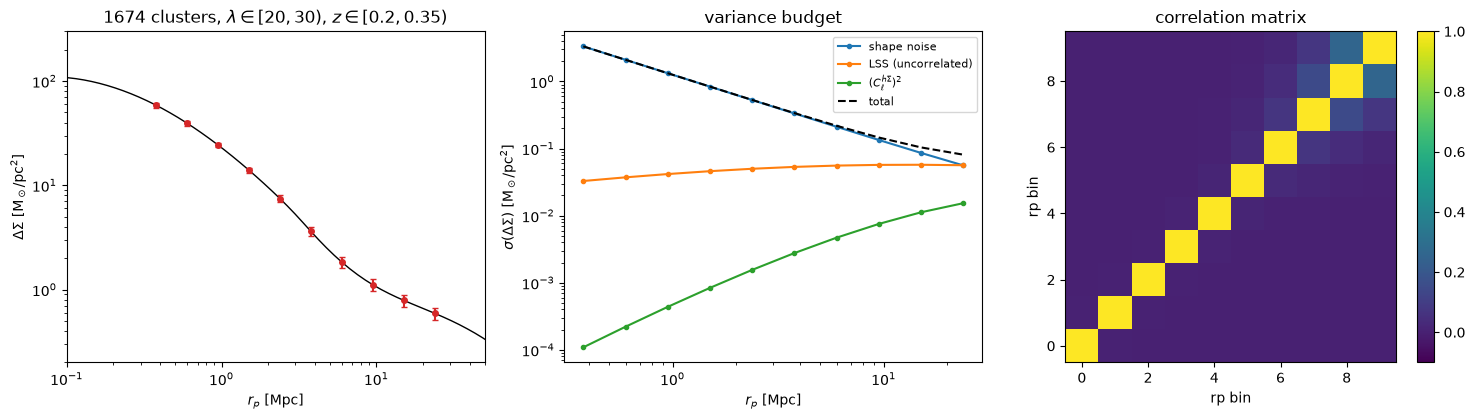

saved clens_demo.png, clens_demo_output.npz


In [6]:
#---------------- plots ----------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].loglog(r, DS, c="k", lw=1)
ax[0].errorbar(rp, DS_bin, np.sqrt(np.diag(cov_tot)), fmt="o", c="C3", ms=4, capsize=2)
ax[0].set(xlim=(0.1, 50), ylim=(0.2, 300), xlabel=r"$r_p$ [Mpc]", ylabel=r"$\Delta\Sigma$ [M$_\odot$/pc$^2$]",
          title=f"{N:.0f} clusters, $\\lambda\\in[{lam_min:.0f},{lam_max:.0f})$, $z\\in[{zh_min},{zh_max})$")
for c, lab in [(cov_sn, "shape noise"), (cov_lss, "LSS (uncorrelated)"), (cov_cross, r"$(C_\ell^{h\Sigma})^2$")]:
    ax[1].loglog(rp, np.sqrt(np.diag(c)), "o-", ms=3, label=lab)
ax[1].loglog(rp, np.sqrt(np.diag(cov_tot)), "k--", label="total")
ax[1].set(xlabel=r"$r_p$ [Mpc]", ylabel=r"$\sigma(\Delta\Sigma)$ [M$_\odot$/pc$^2$]", title="variance budget"); ax[1].legend(fontsize=8)
d = np.sqrt(np.diag(cov_tot)); corr = cov_tot / np.outer(d, d)
im = ax[2].imshow(corr, origin="lower", vmin=-0.1, vmax=1, cmap="viridis")
ax[2].set(title="correlation matrix", xlabel="rp bin", ylabel="rp bin"); plt.colorbar(im, ax=ax[2])
plt.tight_layout()
plt.savefig("clens_demo.png", dpi=150)
plt.show()
print("saved clens_demo.png, clens_demo_output.npz")

## Profile model: HOD richness, projection, miscentering

The stacked profile combines these steps:

$$\langle\Delta\Sigma(R)\rangle=\frac{\int d\ln M\,\frac{dn}{d\ln M}\,P(\lambda\in{\rm bin}|M)\,\Delta\Sigma(R|M)}{\int d\ln M\,\frac{dn}{d\ln M}\,P(\lambda\in{\rm bin}|M)}$$

---

### 1. `clens` default: log-normal (C21)
Costanzi+21, [arXiv:2010.13800](https://arxiv.org/abs/2010.13800), eq. 2 and Table IV:

$$\langle\ln\lambda\rangle=\ln A_\lambda+B_\lambda\ln\frac{M}{3\times10^{14}M_\odot h^{-1}}+C_\lambda\ln\frac{1+z}{1.45},\qquad \sigma^2_{\ln\lambda}=D_\lambda^2+\frac{\langle\lambda\rangle-1}{\langle\lambda\rangle^2}$$

$$P(\lambda_{\min}\le\lambda<\lambda_{\max}|M)=\tfrac12{\rm erfc}\Big(\tfrac{\ln\lambda_{\min}-\langle\ln\lambda\rangle}{\sqrt2\sigma}\Big)-\tfrac12{\rm erfc}\Big(\tfrac{\ln\lambda_{\max}-\langle\ln\lambda\rangle}{\sqrt2\sigma}\Big)$$

Parameters: $A_\lambda=76.3,\ B_\lambda=0.957,\ C_\lambda=0.48,\ D_\lambda=0.217$ (clens's hard-coded default; the `clens` source labels this Table IV column 2, DES-NC+SPT-MOR BKG). Note this $\sigma_{\ln\lambda}$ is calibrated directly against *observed* richness, so it already absorbs whatever projection/measurement scatter is in the data it was fit to — there's no separate true/observed split for this model.

### 2. My change: HOD richness (true)
Costanzi+26, [arXiv:2604.05833](https://arxiv.org/abs/2604.05833), eq. 15. Richness is modelled as a galaxy count: one central plus Poisson satellites.

$$\lambda_{\rm tr}=\lambda_{\rm cen}+\lambda_{\rm sat},\qquad \lambda_{\rm cen}=\begin{cases}1&M\ge M_{\min}\\0&\text{otherwise}\end{cases}$$

$$\langle\lambda_{\rm sat}|M,z\rangle=\Big(\frac{M-M_{\min}}{M_1-M_{\min}}\Big)^{\alpha}\Big(\frac{1+z}{1.45}\Big)^{\epsilon},\qquad P(\lambda_{\rm sat})={\rm Pois}(\mu)\ast\mathcal N(0,\sigma_\lambda\mu),\ \ \mu=\langle\lambda_{\rm sat}\rangle$$

Parameters (C26 mock values): $M_{\min}=10^{11.4}$, $M_1=10^{12.7}\,h^{-1}M_\odot$, $\alpha=0.86$, $\epsilon=0.28$, $\sigma_\lambda=0.185$.

- $M_{\min}$: minimum mass to host a central.
- $M_1$: mass with on average one satellite.
- $\alpha$: slope of the satellite count with mass.
- $\sigma_\lambda$: extra, super-Poisson scatter.

This gives $P(\lambda_{\min}\le\lambda_{\rm tr}<\lambda_{\max}|M,z)$ — i.e. $\lambda_{\rm tr}$ is the **true** richness, with no sky-projection contamination yet.

### 3. My change: projection, $\lambda_{\rm tr}\to\lambda_{\rm ob}$
Costanzi+19, [arXiv:1807.07072](https://arxiv.org/abs/1807.07072), eq. 6 — the same model and the same DES-Y3-calibrated coefficient table (`prj_params_DESY3_lss_lin_dep_getdist_v1.txt`, linearly interpolated over 15 $z$-knots on $[0.10,0.80]$) used in my Buzzard mock (`mocks/mock_cluster_buzzard`, `costanzi_selection.py`). A Gaussian core (background/local structure) plus an exponentially-modified-Gaussian (EMG) tail (line-of-sight projection):

$$P(\lambda_{\rm ob}|\lambda_{\rm tr},z)=(1-f_{\rm prj})\,\mathcal N(\mu,\sigma)+f_{\rm prj}\,{\rm EMG}(\mu,\sigma,\tau)$$

with $\mu=a_\mu+b_\mu\lambda_{\rm tr}$, $\sigma=b_\sigma\lambda_{\rm tr}^{a_\sigma}$, $\tau=b_\tau/\lambda_{\rm tr}^{a_\tau}$, $f_{\rm prj}=b_{\rm prj}/(1+e^{-\lambda_{\rm tr}})^{a_{\rm prj}}$, all $(a,b)$ functions of $z$.

**Implementation** (`hod_richness.py`, `HODRichness._p_bin_obs`): rather than drawing per-halo MC samples as the mock does, clens needs a fast analytic $P(\lambda_{\rm ob}\in{\rm bin}|M,z)$ inside its $\ln M$ integral. For each discrete Poisson satellite count $n$ (so $\lambda_{\rm tr}=\lambda_{\rm cen}+n$), the intrinsic scatter $\sigma_\lambda\mu$ from step 2 is folded in quadrature into the projection kernel's Gaussian-core width (exact for the Gaussian branch, since $\mu(\lambda_{\rm tr})$ is linear; an approximation for the EMG branch, good as long as $\sigma_\lambda\mu\ll\lambda_{\rm tr}$, i.e. away from the $M\sim M_{\min}$ threshold), then the closed-form Gaussian+EMG CDF is evaluated on the bin edges and summed over $n$ with Poisson weights. `exponnorm` from `scipy.stats` supplies the EMG CDF.

`HODRichness(use_projection=True)` (the default) returns $P(\lambda_{\rm ob}\in{\rm bin}|M,z)$; `use_projection=False` recovers the pure TRUE-richness selection of step 2. `enable_hod_hook()` makes clens use whichever is active in counts, bias (and so the covariance) and the profile.

**Effect:** projection is an Eddington-bias-like effect — it lets lower-mass, less-biased halos leak into the $\lambda_{\rm ob}$ bin through the EMG tail, pulling $\langle M\rangle$ and $\bar b$ down and $N$ up relative to the true-richness-only selection (see table below). This moves the HOD prediction *toward* C21, consistent with C21's own scatter already implicitly including projection-like effects (see note in step 1).

### 4. My change: miscentering
DES Y1: McClintock+19 Sec. 5.2, [arXiv:1805.00039](https://arxiv.org/abs/1805.00039). Prior from Zhang+19, [arXiv:1901.07119](https://arxiv.org/abs/1901.07119).

$$\Sigma_{\rm mis}(R|R_{\rm mis})=\frac1{2\pi}\int_0^{2\pi}\Sigma\Big(\sqrt{R^2+R_{\rm mis}^2+2RR_{\rm mis}\cos\phi}\Big)d\phi$$

$$P(x|\tau)=\frac{x}{\tau^2}e^{-x/\tau},\quad x=\frac{R_{\rm mis}}{R_\lambda},\quad R_\lambda=\Big(\frac{\lambda}{100}\Big)^{0.2}h^{-1}{\rm Mpc}\ ({\rm physical})$$

$$\Sigma_{\rm mis}(R)=\int dx\,P(x|\tau)\,\Sigma_{\rm mis}(R|xR_\lambda),\qquad \Delta\Sigma_{\rm obs}=(1-f_{\rm mis})\,\Delta\Sigma_{\rm cen}+f_{\rm mis}\,\Delta\Sigma_{\rm mis}$$

DES Y1 values: $f_{\rm mis}=0.165$ (from $\rho=0.835$), $\tau=0.166$.

Effect: about −16% at small $r_p$, gone beyond about 2 cMpc.

**Units:** clens is $h$-free comoving, so $R_\lambda^{\rm com}=R_\lambda(1+z)/h$.

---

**Results for $\lambda\in[20,30)$, $z\in[0.2,0.35)$:**

| Model | $N$ | $\bar b$ | $\langle M\rangle$ |
|---|---|---|---|
| C21 (clens default) | 1674 | 2.50 | $1.1\times10^{14}M_\odot$ |
| HOD, true $\lambda_{\rm tr}$ only (no projection) | 615 | 3.29 | $2.2\times10^{14}M_\odot$ |
| HOD + projection (default, used below) | 912 | 2.93 | $1.6\times10^{14}M_\odot$ |

Two effects set the remaining HOD–C21 gap: (i) parameter calibration, not functional form — at fixed $M$, the C26 mock HOD gives about half the richness of C21, so selecting the same $\lambda$ range still needs higher mass than C21 predicts; (ii) adding projection narrows but doesn't close that gap, since it pulls in lower-mass halos via the EMG tail but the underlying mock-HOD mass-richness normalization is still different from C21's fitted one.


In [7]:
# Comparison cell: clens default (C21 log-normal) vs HOD vs HOD+miscentering
# needs from earlier cells: co, su, fsky, area, zh_min, zh_max, lam_min, lam_max, rp_min, rp_max, n_rp, np, plt
from hod_richness import HODRichness, enable_hod_hook
from miscentering import sigma_and_deltasigma, miscentered_DeltaSigma, R_lambda_comoving
enable_hod_hook()

In [8]:
models = {"clens default: C21 log-normal": Costanzi21ScalingRelation(),
          "HOD (C26 eq.15)": HODRichness(h=co.h)}
res = {}
for name, sr in models.items():
    N, _, b, lnM, _ = ClusterCounts(co, sr).calc_counts(zh_min, zh_max, lam_min, lam_max, area)
    lp = LensingProfiles(co=co, su=su, sr=sr, zh_min=zh_min, zh_max=zh_max,
                         lambda_min=lam_min, lambda_max=lam_max)
    r, Sig, DS = sigma_and_deltasigma(lp)
    cds = CovDeltaSigma(co=co, su=su, sr=sr, fsky=fsky)          # covariance consistent with THIS model
    rpb, _, _ = cds.calc_cov(rp_min=rp_min, rp_max=rp_max, n_rp=n_rp, zh_min=zh_min, zh_max=zh_max,
                             lambda_min=lam_min, lambda_max=lam_max)
    res[name] = dict(N=N, b=b, M=np.exp(lnM), r=r, Sig=Sig, DS=DS, rpb=rpb, err=np.sqrt(np.diag(cds.cov_sum)))

h = res["HOD (C26 eq.15)"]
lam_mid, z_mid = 0.5*(lam_min+lam_max), 0.5*(zh_min+zh_max)
h["DS_mis"], _, h["DS_cen"] = miscentered_DeltaSigma(h["r"], h["Sig"], R_lambda_comoving(lam_mid, z_mid, co.h),
                                           tau=0.166, f_mis=0.165)
for k, v in res.items():
    print(f"{k:32s} N={v['N']:6.0f}  <b>={v['b']:.2f}  <M>={v['M']:.2e} Msun")

vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


fsky 0.03483383026688968


mean_Sigma_crit 2145.28
vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


vol 0.30025038235628115


... (5 outputs left out)

counts 912.3916065076223 for 20.0, 30.0, 1437.0


vol 0.30025038235628115


counts 912.3916065076223 for 20.0, 30.0, 1437.0


clens default: C21 log-normal    N=  1674  <b>=2.50  <M>=1.09e+14 Msun
HOD (C26 eq.15)                  N=   912  <b>=2.93  <M>=1.61e+14 Msun


/tmp/ipykernel_1379157/245628142.py:13: RuntimeWarning: invalid value encountered in divide
  ax[1].semilogx(h["r"], h["DS_mis"]/h["DS_cen"], "C1--", label="HOD+mis / HOD  (miscentering)")


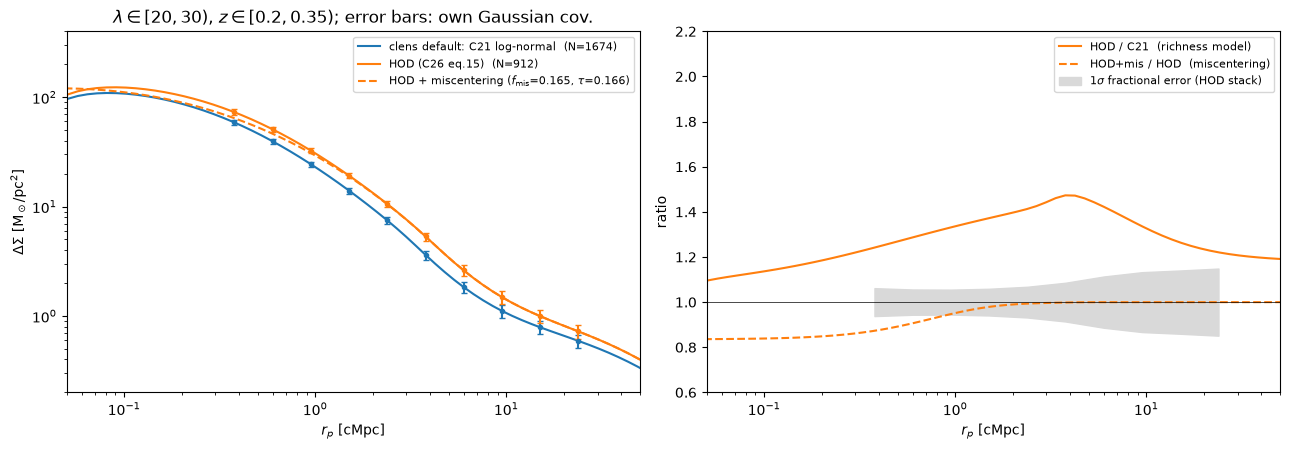

In [9]:
# ---- plot ----
c21 = res["clens default: C21 log-normal"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for (k, v), col in zip(res.items(), ["C0", "C1"]):
    ax[0].loglog(v["r"], v["DS"], c=col, label=f"{k}  (N={v['N']:.0f})")
    ax[0].errorbar(v["rpb"], np.interp(v["rpb"], v["r"], v["DS"]), v["err"], fmt="o", ms=3, c=col, capsize=2)
ax[0].loglog(h["r"], h["DS_mis"], "C1--", label=r"HOD + miscentering ($f_{\rm mis}$=0.165, $\tau$=0.166)")
ax[0].set(xlim=(0.05, 50), ylim=(0.2, 400), xlabel=r"$r_p$ [cMpc]", ylabel=r"$\Delta\Sigma$ [M$_\odot$/pc$^2$]",
          title=rf"$\lambda\in[{lam_min:.0f},{lam_max:.0f})$, $z\in[{zh_min},{zh_max})$; error bars: own Gaussian cov.")
ax[0].legend(fontsize=8)

ax[1].semilogx(h["r"], h["DS"]/np.interp(h["r"], c21["r"], c21["DS"]), "C1", label="HOD / C21  (richness model)")
ax[1].semilogx(h["r"], h["DS_mis"]/h["DS_cen"], "C1--", label="HOD+mis / HOD  (miscentering)")
fe = h["err"]/np.interp(h["rpb"], h["r"], h["DS"])
ax[1].fill_between(h["rpb"], 1-fe, 1+fe, color="0.85", label=r"1$\sigma$ fractional error (HOD stack)")
ax[1].axhline(1, c="k", lw=.5)
ax[1].set(xlim=(0.05, 50), ylim=(0.6, 2.2), xlabel=r"$r_p$ [cMpc]", ylabel="ratio"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("clens_vs_hod_mis.png", dpi=150); plt.show()

In [10]:
sr  = HODRichness(h=co.h)
cds = CovDeltaSigma(co=co, su=su, sr=sr, fsky=fsky)
rp, cov_lss, cov_shape = cds.calc_cov(rp_min=0.3, rp_max=30, n_rp=10,
                                      zh_min=0.20, zh_max=0.35,
                                      lambda_min=20, lambda_max=30)
cov = cds.cov_sum          # = cov_shape + cov_lss + cds.cov_cross  ← use this

fsky 0.03483383026688968


mean_Sigma_crit 2145.28
vol 0.30025038235628115


counts 912.3916065076223 for 20, 30, 1437.0


vol 0.30025038235628115


counts 912.3916065076223 for 20, 30, 1437.0


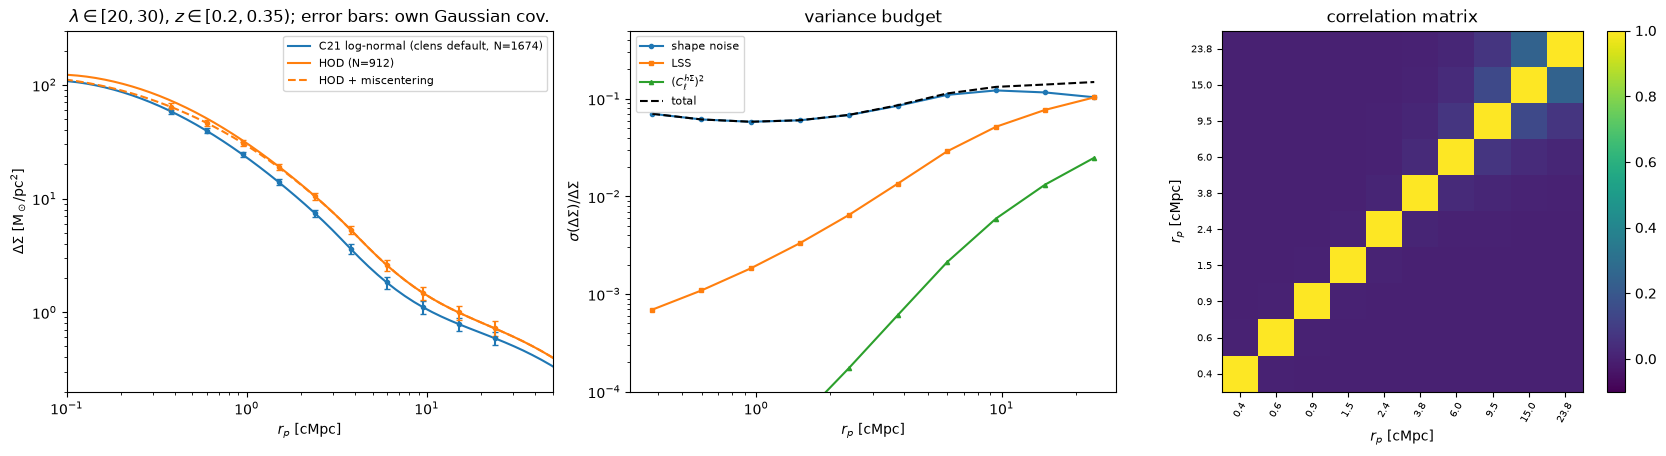

In [11]:
# ---- HOD (+ miscentering) covariance: clens Gaussian, Wu+19 eq. 22 ----
cov_cross = cds.cov_cross
cov       = cds.cov_sum                       # shape + LSS + cross
err       = np.sqrt(np.diag(cov))
corr      = cov / np.outer(err, err)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# (1) mean profiles with error bars from each model's own covariance
c21 = res["clens default: C21 log-normal"]
DS_c21 = np.interp(rp, c21["r"], c21["DS"])
DS_hod = np.interp(rp, h["r"], h["DS"])
DS_mis = np.interp(rp, h["r"], h["DS_mis"])

ax[0].loglog(c21["r"], c21["DS"], "C0", label=f"C21 log-normal (clens default, N={c21['N']:.0f})")
ax[0].errorbar(rp, DS_c21, c21["err"], fmt="o", c="C0", ms=3, capsize=2)
ax[0].loglog(h["r"], h["DS"],     "C1",   label=f"HOD (N={h['N']:.0f})")
ax[0].loglog(h["r"], h["DS_mis"], "C1--", label="HOD + miscentering")
ax[0].errorbar(rp, DS_mis, err, fmt="o", c="C1", ms=3, capsize=2)
ax[0].set(xlim=(0.1, 50), ylim=(0.2, 300), xlabel=r"$r_p$ [cMpc]",
          ylabel=r"$\Delta\Sigma$ [M$_\odot$/pc$^2$]",
          title=rf"$\lambda\in[{lam_min:.0f},{lam_max:.0f})$, $z\in[{zh_min},{zh_max})$; error bars: own Gaussian cov.")
ax[0].legend(fontsize=8)

# (2) variance budget, as fraction of the signal
for c, lab, sty in [(cov_shape, "shape noise", "o-"), (cov_lss, "LSS", "s-"),
                    (cov_cross, r"$(C_\ell^{h\Sigma})^2$", "^-"), (cov, "total", "k--")]:
    ax[1].loglog(rp, np.sqrt(np.diag(c)) / DS_mis, sty, ms=3, label=lab)
ax[1].set(xlabel=r"$r_p$ [cMpc]", ylabel=r"$\sigma(\Delta\Sigma)/\Delta\Sigma$",
          ylim=(1e-4, 0.5), title="variance budget")
ax[1].legend(fontsize=8)

# (3) correlation matrix
im = ax[2].imshow(corr, origin="lower", vmin=-0.1, vmax=1, cmap="viridis")
ax[2].set_xticks(range(len(rp))); ax[2].set_xticklabels([f"{x:.1f}" for x in rp], rotation=60, fontsize=7)
ax[2].set_yticks(range(len(rp))); ax[2].set_yticklabels([f"{x:.1f}" for x in rp], fontsize=7)
ax[2].set(xlabel=r"$r_p$ [cMpc]", ylabel=r"$r_p$ [cMpc]", title="correlation matrix")
plt.colorbar(im, ax=ax[2])

plt.tight_layout()
plt.savefig("cov_hod.png", dpi=150)          # save before show
plt.show()

np.savez("cov_hod.npz", rp=rp, cov=cov, cov_shape=cov_shape, cov_lss=cov_lss, cov_cross=cov_cross)

In [ ]:
from matplotlib.colors import LogNorm

# --- DES Y1 binning (McClintock+19): 15 log bins, ~0.03-30 Mpc (comoving) ---
rp_min_y1, rp_max_y1, n_rp_y1 = 0.0323, 30., 15
edges_com = np.exp(np.linspace(np.log(rp_min_y1), np.log(rp_max_y1), n_rp_y1 + 1))
edges = edges_com / (1. + 0.5*(zh_min+zh_max))   # comoving -> physical Mpc at z_mid

# --- full (off-diagonal) clens covariance with the HOD sample; takes ~1 min ---
sr  = HODRichness(h=co.h)
cds = CovDeltaSigma(co=co, su=su, sr=sr, fsky=fsky)
rp15, cov_lss15, cov_sn15 = cds.calc_cov(rp_min=rp_min_y1, rp_max=rp_max_y1, n_rp=n_rp_y1,
                                         zh_min=zh_min, zh_max=zh_max,
                                         lambda_min=lam_min, lambda_max=lam_max,
                                         diag_only=False)
cov_cross15 = cds.cov_cross
cov_tot15   = cds.cov_sum

# --- 2x2 panels, same order as DES Y1 Fig. 6 ---
panels = [("Shape noise",                          cov_sn15),
          (r"$(C_\ell^{h\Sigma})^2$ (linear bias)", cov_cross15),
          ("Total",                                cov_tot15),
          ("uLSS",                                 cov_lss15)]

vmax = max(np.abs(c).max() for _, c in panels)
norm = LogNorm(vmin=1e-4, vmax=vmax)          # one shared log colour scale
lge  = np.log10(edges)                        # pixel edges in log10 R (physical Mpc)

fig, axes = plt.subplots(2, 2, figsize=(8.2, 7.6), sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.06, hspace=0.18))
for ax, (title, c) in zip(axes.flat, panels):
    im = ax.pcolormesh(lge, lge, np.clip(np.abs(c), 1e-30, None), norm=norm, cmap="plasma")
    ax.set_title(title, fontsize=12)
    ax.set_aspect("equal")
for ax in axes[1]:    ax.set_xlabel(r"$\log_{10} R$ [Mpc]")
for ax in axes[:, 0]: ax.set_ylabel(r"$\log_{10} R$ [Mpc]")
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.03)
cb.set_label(r"$|{\rm Cov}|$  [(M$_\odot$/pc$^2$)$^2$]")
fig.suptitle(rf"$\lambda\in[{lam_min:.0f},{lam_max:.0f})$, $z\in[{zh_min},{zh_max})$, HOD", y=0.98)
plt.savefig("cov_components_desy1_style.png", dpi=150, bbox_inches="tight")
plt.show()

vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


fsky 0.03483383026688968


mean_Sigma_crit 2145.28
vol 0.30025038235628115


counts 1673.990098915302 for 20.0, 30.0, 1437.0


vol 0.30025038235628115


... (5 outputs left out)

counts 912.3916065076223 for 20.0, 30.0, 1437.0


vol 0.30025038235628115


counts 912.3916065076223 for 20.0, 30.0, 1437.0


C21 (clens default)    N= 1674  b=2.50  sigma/DS: [0.057 0.053 0.054 0.06  0.071 0.094 0.119 0.131 0.132 0.137]
HOD                    N=  912  b=2.93  sigma/DS: [0.062 0.056 0.055 0.059 0.068 0.086 0.114 0.133 0.14  0.149]
HOD + miscentering     N=  912  b=2.93  sigma/DS: [0.07  0.062 0.058 0.06  0.068 0.086 0.113 0.133 0.14  0.149]


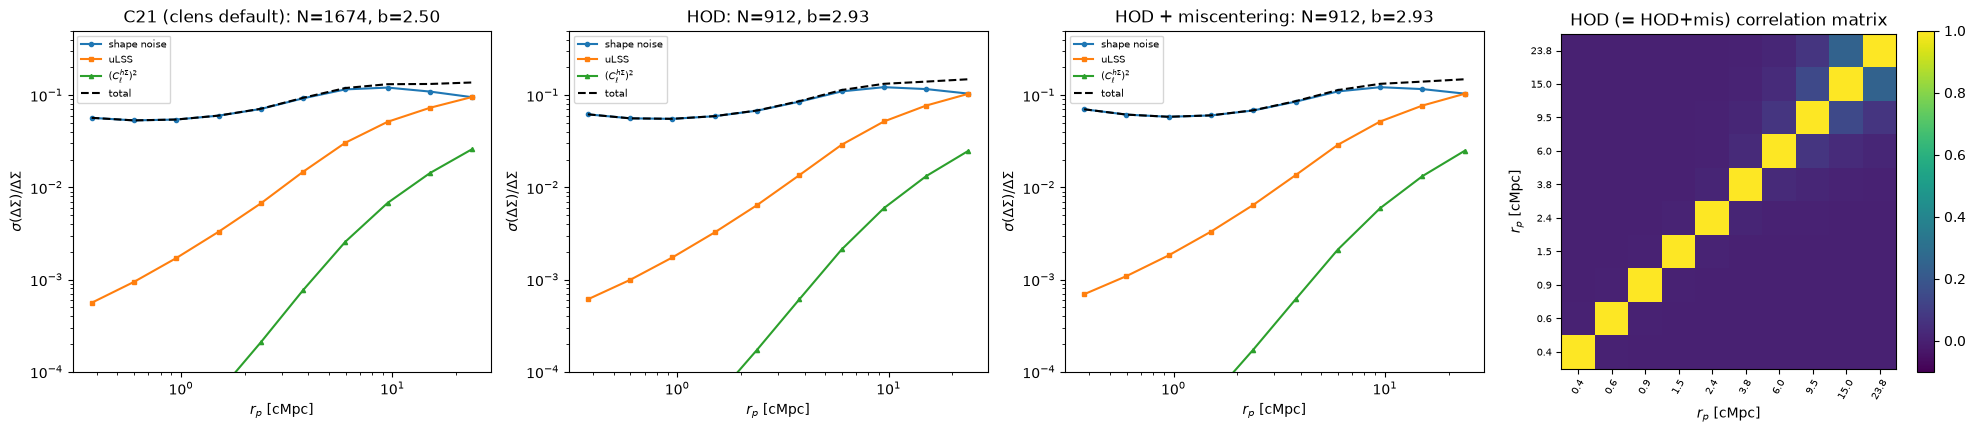

In [13]:
lam_mid, z_mid = 0.5*(lam_min+lam_max), 0.5*(zh_min+zh_max)
models = {"C21 (clens default)": Costanzi21ScalingRelation(), "HOD": HODRichness(h=co.h)}
cov = {}
for name, sr in models.items():
    N, _, b, _, _ = ClusterCounts(co, sr).calc_counts(zh_min, zh_max, lam_min, lam_max, area)
    lp = LensingProfiles(co=co, su=su, sr=sr, zh_min=zh_min, zh_max=zh_max,
                         lambda_min=lam_min, lambda_max=lam_max)
    r, Sig, DS = sigma_and_deltasigma(lp)
    cds = CovDeltaSigma(co=co, su=su, sr=sr, fsky=fsky)
    rpb, _, _ = cds.calc_cov(rp_min=rp_min, rp_max=rp_max, n_rp=n_rp, zh_min=zh_min, zh_max=zh_max,
                             lambda_min=lam_min, lambda_max=lam_max)
    cov[name] = dict(N=N, b=b, r=r, DS=DS, rp=rpb, mean=np.interp(rpb, r, DS),
                     shape=cds.cov_shape_noise, lss=cds.cov_cosmic_shear, cross=cds.cov_cross, total=cds.cov_sum)
 
# HOD + miscentering: SAME covariance as HOD (miscentering only changes the mean)
h = cov["HOD"]
_, Sig_hod, _ = sigma_and_deltasigma(LensingProfiles(co=co, su=su, sr=models["HOD"], zh_min=zh_min,
                                    zh_max=zh_max, lambda_min=lam_min, lambda_max=lam_max))
DS_mis, _, _ = miscentered_DeltaSigma(h["r"], Sig_hod, R_lambda_comoving(lam_mid, z_mid, co.h),
                                      tau=0.166, f_mis=0.165)
cov["HOD + miscentering"] = dict(h, DS=DS_mis, mean=np.interp(h["rp"], h["r"], DS_mis))
 
for k, v in cov.items():
    print(f"{k:22s} N={v['N']:5.0f}  b={v['b']:.2f}  sigma/DS: {np.round(np.sqrt(np.diag(v['total']))/v['mean'], 3)}")
 
# ---- plot: variance budget (fractional) for each model + correlation matrix ----
fig, ax = plt.subplots(1, 4, figsize=(20, 4.4))
for a, (name, c) in zip(ax[:3], cov.items()):
    for key, lab, sty in [("shape", "shape noise", "o-"), ("lss", "uLSS", "s-"),
                          ("cross", r"$(C_\ell^{h\Sigma})^2$", "^-"), ("total", "total", "k--")]:
        a.loglog(c["rp"], np.sqrt(np.diag(c[key])) / c["mean"], sty, ms=3, label=lab)
    a.set(title=f"{name}: N={c['N']:.0f}, b={c['b']:.2f}", xlabel=r"$r_p$ [cMpc]",
          ylabel=r"$\sigma(\Delta\Sigma)/\Delta\Sigma$", ylim=(1e-4, 0.5))
    a.legend(fontsize=7)
d = np.sqrt(np.diag(h["total"]))
im = ax[3].imshow(h["total"] / np.outer(d, d), origin="lower", vmin=-0.1, vmax=1)
ax[3].set_xticks(range(len(h["rp"]))); ax[3].set_xticklabels([f"{x:.1f}" for x in h["rp"]], rotation=60, fontsize=7)
ax[3].set_yticks(range(len(h["rp"]))); ax[3].set_yticklabels([f"{x:.1f}" for x in h["rp"]], fontsize=7)
ax[3].set(title="HOD (= HOD+mis) correlation matrix", xlabel=r"$r_p$ [cMpc]", ylabel=r"$r_p$ [cMpc]")
plt.colorbar(im, ax=ax[3])
plt.tight_layout(); plt.savefig("cov_budget_nointr.png", dpi=150); plt.show()

In [ ]:
# --- DES Y1 binning (McClintock+19): 15 log bins, ~0.03-30 Mpc (comoving) ---
rp_min_y1, rp_max_y1, n_rp_y1 = 0.0323, 30., 15
edges_com = np.exp(np.linspace(np.log(rp_min_y1), np.log(rp_max_y1), n_rp_y1 + 1))
edges = edges_com / (1. + 0.5*(zh_min+zh_max))   # comoving -> physical Mpc at z_mid
lge   = np.log10(edges)

# --- full clens covariance for each model (~1 min each) ---
models = {"C21": Costanzi21ScalingRelation(),
          "HOD (= HOD + mis)": HODRichness(h=co.h)}     # miscentering doesn't change the cov
cov15 = {}
for name, sr in models.items():
    cds = CovDeltaSigma(co=co, su=su, sr=sr, fsky=fsky)
    rp15, cov_lss15, cov_sn15 = cds.calc_cov(rp_min=rp_min_y1, rp_max=rp_max_y1, n_rp=n_rp_y1,
                                             zh_min=zh_min, zh_max=zh_max,
                                             lambda_min=lam_min, lambda_max=lam_max,
                                             diag_only=False)
    cov15[name] = [("Shape noise",                          cov_sn15),
                   (r"$(C_\ell^{h\Sigma})^2$ (linear bias)", cds.cov_cross),
                   ("Total",                                cds.cov_sum),
                   ("uLSS",                                 cov_lss15)]

# --- one shared log colour scale across BOTH models ---
vmax = max(np.abs(c).max() for panels in cov15.values() for _, c in panels)
norm = LogNorm(vmin=1e-4, vmax=vmax)

for name, panels in cov15.items():
    fig, axes = plt.subplots(2, 2, figsize=(8.2, 7.6), sharex=True, sharey=True,
                             gridspec_kw=dict(wspace=0.06, hspace=0.18))
    for ax, (title, c) in zip(axes.flat, panels):
        im = ax.pcolormesh(lge, lge, np.clip(np.abs(c), 1e-30, None), norm=norm, cmap="plasma")
        ax.set_title(title, fontsize=12)
        ax.set_aspect("equal")
    for ax in axes[1]:    ax.set_xlabel(r"$\log_{10} R$ [Mpc]")
    for ax in axes[:, 0]: ax.set_ylabel(r"$\log_{10} R$ [Mpc]")
    cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.03)
    cb.set_label(r"$|{\rm Cov}|$  [(M$_\odot$/pc$^2$)$^2$]")
    fig.suptitle(rf"$\lambda\in[{lam_min:.0f},{lam_max:.0f})$, $z\in[{zh_min},{zh_max})$, {name}", y=0.98)
    tag = name.split()[0]                                   # "C21" or "HOD"
    plt.savefig(f"cov_components_desy1_style_{tag}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Full covariance: Gaussian + intrinsic (`intrinsic_cov.py`)

`CovStackedDeltaSigma` = clens Gaussian (`cov_stat`: shape noise + LSS + $(C_\ell^{h\Sigma})^2$) plus the halo-to-halo terms from `IntrinsicCov`,
split with the law of total covariance (nested $M\to c\to R_{\rm mis}$, each $/N$):

- `cov_lambdaM` $={\rm Cov}_M[\,E(\Delta\Sigma|M)\,]$: spread of halo mass inside the richness bin (HOD + projection here)
- `cov_cM` $=E_M[{\rm Cov}_c(\ldots)]$: Duffy+08 $c_{200m}(M,z)$ with log-normal scatter $\sigma_{\ln c}=0.35$
- `cov_miscen`: DES Y1 miscentering, $f_{\rm mis}=0.165$, $\tau=0.166$

plus the two Gruen+15 ([arXiv:1501.01632](https://arxiv.org/abs/1501.01632)) terms, each from its own calculator and combined with `CovStackedDeltaSigma.merge`:

- `cov_ell` (`halo_ell_cov.HaloEllCov`, Gruen+15 $C^{\rm ell}$): prolate NFW (truncated at $r_{200m}$) with axis ratio $q\sim\mathcal N(0.6,0.12)$ on $[0.1,1]$ and isotropic orientation; ${\rm Cov}_{q,\alpha}$ at fixed $M$, averaged over the bin's mass distribution; amplitude $c_{\rm ell}=3.7$ (Gruen+15 simulation fit; 1 = analytic)
- `cov_clss` (`clss_cov.CLSSCov`, Gruen+15 $C^{\rm corr}$): Poisson scatter in the number of neighbour haloes clustered around the cluster, $b_{\rm cl}\,b(M)\,n(M)\,w_p(R_{\rm off})$ with $\Pi=\pm200\,h^{-1}$Mpc, $10^9$–$10^{15.5}\,h^{-1}M_\odot$; not in the clens Gaussian part; amplitude $c_{\rm corr}=5.0$ (Gruen+15 fit; 1 = analytic lower limit)

Both use the analytic NFW in `nfw_profile.py` (ported from CLensPy, with truncated $\Sigma$ and $M_{\rm 2D}$ added).

Output is in $h$-units ($R$ in comoving Mpc/$h$, covariance in $(h\,M_\odot/{\rm pc}^2)^2$), DES Y1 15-bin binning.


In [ ]:
# ---- full covariance as CovStackedDeltaSigma: clens Gaussian (stat) + intrinsic (lambda-M, c-M, miscentering)
#      + Gruen+15 halo ellipticity (ell) and correlated LSS (clss) ----
# needs: co, su, fsky, area, zh_min, zh_max, lam_min, lam_max, and enable_hod_hook() from above
from intrinsic_cov import IntrinsicCov, CovStackedDeltaSigma
from halo_ell_cov import HaloEllCov
from clss_cov import CLSSCov

# DES Y1 binning (McClintock+19 Sec. 3.1): 15 log bins, 0.0323-30 PHYSICAL Mpc (h-free, H0=70).
# clens works in comoving Mpc, so the edges are scaled by (1 + z_mid); intrinsic terms matter at small R
z_mid_i = 0.5 * (zh_min + zh_max)
rp_min_i, rp_max_i, n_rp_i = 0.0323 * (1 + z_mid_i), 30. * (1 + z_mid_i), 15
edges_i = np.exp(np.linspace(np.log(rp_min_i), np.log(rp_max_i), n_rp_i + 1))   # same bins clens uses

sr_i = HODRichness(h=co.h)
N_i, _, b_i, _, _ = ClusterCounts(co, sr_i).calc_counts(zh_min, zh_max, lam_min, lam_max, area)

# stat: shape noise + LSS + (C_ell^hSigma)^2, full off-diagonal (~1 min)
cds_i = CovDeltaSigma(co=co, su=su, sr=sr_i, fsky=fsky)
cds_i.calc_cov(rp_min=rp_min_i, rp_max=rp_max_i, n_rp=n_rp_i, zh_min=zh_min, zh_max=zh_max,
               lambda_min=lam_min, lambda_max=lam_max, diag_only=False)

# intrinsic: Duffy+08 c(M) with log-normal scatter, DES Y1 miscentering
ic = IntrinsicCov(co, sr_i, zh_min, zh_max, lam_min, lam_max,
                  f_mis=0.165, tau=0.166,
                  include_concentration=True, cM="duffy08", sigma_lnc=0.35)
# Gruen+15: halo ellipticity + orientation, and correlated LSS (~10 s each, ~1 GB peak for CLSSCov)
he = HaloEllCov(co, sr_i, zh_min, zh_max, lam_min, lam_max, c_ell=3.7)      # c_ell=1 -> analytic only
cl = CLSSCov(co, sr_i, zh_min, zh_max, lam_min, lam_max, c_corr=5.0)        # c_corr=1 -> analytic lower limit

# each calculator returns a CovStackedDeltaSigma (h-units: Mpc/h, (h Msun/pc^2)^2) with cov_stat + its own
# components; merge checks that the binning and cov_stat agree and combines them into one object
cov_stk = ic.calc_cov(edges_i, N_i, cov_stat=cds_i.cov_sum).merge(
    he.calc_cov(edges_i, N_i, cov_stat=cds_i.cov_sum),
    cl.calc_cov(edges_i, N_i, cov_stat=cds_i.cov_sum))
cov_stk.save("cov_stacked_hod.npz")

print(f"HOD + miscentering: N={N_i:.0f}, b={b_i:.2f} (CLSSCov b_cl={cl.b_cl:.2f}); components: {list(cov_stk.components())}")
print("share of total variance at each R:")
for k, f in cov_stk.frac_diag().items():
    print(f"  {k:12s}", np.round(f, 3))


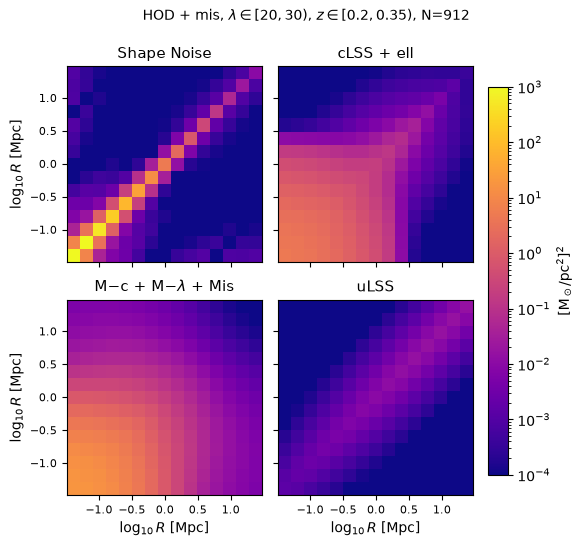

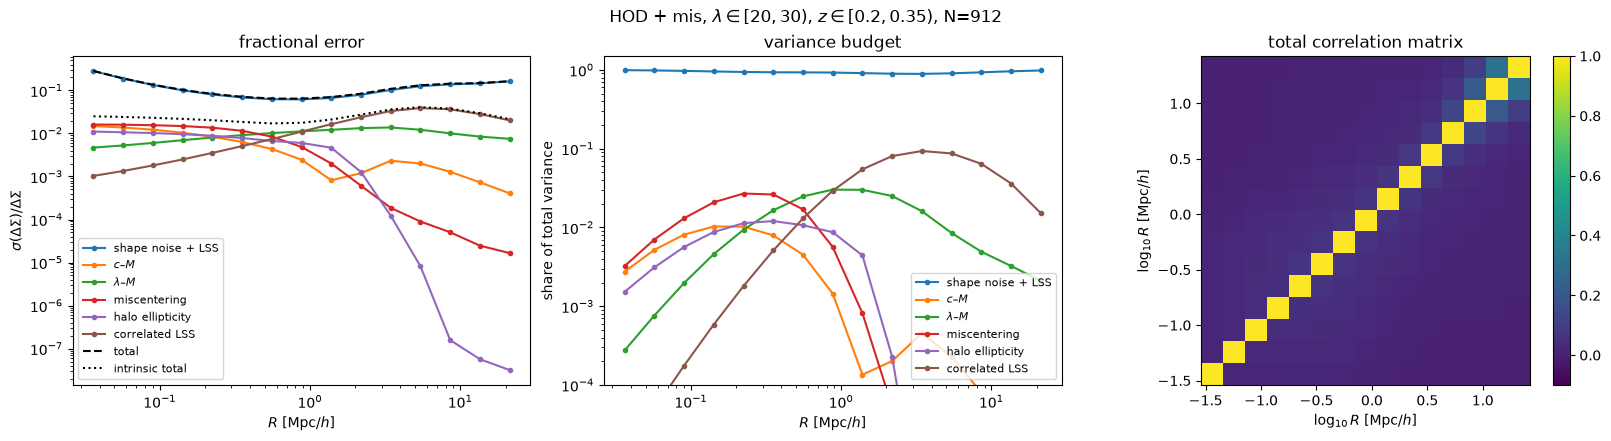

In [10]:
# ---- plot each CovStackedDeltaSigma component separately ----
from matplotlib.colors import LogNorm

R   = cov_stk.R_hiMpc
lge = np.log10(edges_i * co.h)                     # bin edges, log10 comoving Mpc/h
names = list(cov_stk.components()) + ["total"]
title = rf"HOD + mis, $\lambda\in[{lam_min:.0f},{lam_max:.0f})$, $z\in[{zh_min},{zh_max})$, N={N_i:.0f}"

# (1) DES Y1 Fig. 6 layout (McClintock+19): 2x2 panels, physical Mpc, h-free, [Msun/pc^2]^2, plasma, log 1e-4..1e3
#     clens/IntrinsicCov are comoving: R_phys = R_com/(1+z), DeltaSigma_phys = DeltaSigma_com (1+z)^2  -> Cov x (1+z)^4
a_i     = 1 + z_mid_i
lge_y1  = np.log10(edges_i / a_i)                      # physical Mpc
to_y1   = (co.h * a_i**2)**2                           # cov_stk (h Msun/pc^2)^2 comoving -> (Msun/pc^2)^2 physical
# uLSS: M19 measured it from log-normal simulations of the whole stack, which also contains the clens
# (C_ell^hSigma)^2 sample-variance term, so both clens LSS pieces go in that panel
y1_panels = [("Shape Noise",                cds_i.cov_shape_noise * a_i**4),
             ("cLSS + ell",                 cov_stk.total(include=["clss", "ell"]) * to_y1),
             (r"M$-$c + M$-\lambda$ + Mis",  cov_stk.total(include=["cM", "lambdaM", "miscen"]) * to_y1),
             ("uLSS",                       (cds_i.cov_cosmic_shear + cds_i.cov_cross) * a_i**4)]
norm_y1 = LogNorm(vmin=1e-4, vmax=1e3)

fig, axes = plt.subplots(2, 2, figsize=(6.4, 5.6), sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.08, hspace=0.18))
for ax, (ttl, C) in zip(axes.flat, y1_panels):
    im = ax.pcolormesh(lge_y1, lge_y1, np.clip(np.abs(C), 1e-30, None), norm=norm_y1, cmap="plasma")
    ax.set_title(ttl, fontsize=11)
    ax.set_aspect("equal")
    ax.set_xticks([-1, -0.5, 0, 0.5, 1]); ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.tick_params(labelsize=8)
for ax in axes[1]:    ax.set_xlabel(r"$\log_{10} R$ [Mpc]")
for ax in axes[:, 0]: ax.set_ylabel(r"$\log_{10} R$ [Mpc]")
cb = fig.colorbar(im, ax=axes, shrink=0.9, pad=0.03)
cb.set_label(r"[M$_\odot$/pc$^2$]$^2$")
fig.suptitle(rf"HOD + mis, $\lambda\in[{lam_min:.0f},{lam_max:.0f})$, $z\in[{zh_min},{zh_max})$, N={N_i:.0f}", fontsize=10)
plt.savefig("cov_stacked_components.png", dpi=150, bbox_inches="tight"); plt.show()

# (2) diagonal: fractional error per component, and share of the total variance
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), constrained_layout=True)
for k, C in cov_stk.components().items():
    ax[0].loglog(R, np.sqrt(np.diag(C)) / cov_stk.DeltaSigma, "o-", ms=3, label=cov_stk.label(k))
ax[0].loglog(R, np.sqrt(np.diag(cov_stk.total())) / cov_stk.DeltaSigma, "k--", label="total")
ax[0].loglog(R, np.sqrt(np.diag(cov_stk.total(include=["lambdaM", "cM", "miscen", "ell", "clss"]))) / cov_stk.DeltaSigma,
             "k:", label="intrinsic total")
ax[0].set(xlabel=r"$R$ [Mpc/$h$]", ylabel=r"$\sigma(\Delta\Sigma)/\Delta\Sigma$", title="fractional error")
ax[0].legend(fontsize=8)

for k, f in cov_stk.frac_diag().items():
    ax[1].loglog(R, f, "o-", ms=3, label=cov_stk.label(k))
ax[1].set(ylim=(1e-4, 1.5), xlabel=r"$R$ [Mpc/$h$]", ylabel="share of total variance", title="variance budget")
ax[1].legend(fontsize=8)

# (3) correlation matrix of the total
d = np.sqrt(np.diag(cov_stk.total()))
im = ax[2].pcolormesh(lge, lge, cov_stk.total() / np.outer(d, d), vmin=-0.1, vmax=1, cmap="viridis")
ax[2].set(aspect="equal", xlabel=r"$\log_{10} R$ [Mpc/$h$]", ylabel=r"$\log_{10} R$ [Mpc/$h$]",
          title="total correlation matrix")
fig.colorbar(im, ax=ax[2])
fig.suptitle(title)
plt.savefig("cov_stacked_budget.png", dpi=150, bbox_inches="tight"); plt.show()
